<a href="https://colab.research.google.com/github/YYahran/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [10]:
!python --version

Python 3.11.13


In [11]:
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
!pip install vllm transformers==4.52.4
# 필요 시 세션 재시작

In [12]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 393 not upgraded.


- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [2]:
!pip install google-colab-selenium lxml

## 13-2 웹 스크래핑 함수 정의 및 실행

In [3]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url):
    # url 페이지로 이동
    driver.get(url)

    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source

    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content)

    return tree

## HTML 트리에서 제목 추출
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > strong > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class="td-subject"]/a/strong/text()')
    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

In [4]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd

## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):
    # _listNext 클래스를 기준으로 엘리먼트 선택
    next_page_link = driver.find_element(By.CLASS_NAME, "_listNext")
    if next_page_link and next_page_link.is_enabled():
        # 다음 페이지 버튼 클릭
        next_page_link.click()
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        )
        page_content = driver.page_source
        tree = html.fromstring(page_content)
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False):
    # verbose: 함수 내부의 상태 출력 여부
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 13-2 에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)
        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)
        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles)
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
=== 페이지 2 처리중입니다. ===
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과 과제&기출 창고
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
극예술연구회   회원모집
 ★ 극예술연구회 ★ 연극동아리 49기 신입 회원 모집
=== 페이지 3 처리중입니다. ===
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과 과제&기출 창고
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
극예술연구회   회원모집
 ★ 극예술연구회 ★ 연극동아리 49기 

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제

In [5]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
       # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
        text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)
       # HTML 태그 제거 regex
        text = re.sub(r'<[^>]*>', '', text)
       # 소문자로 변환 python 함수
        text = text.lower()
        return text
    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집
...,...,...
95,🍀크로바 네이버 카페,크로바 네이버 카페
96,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다
97,2학기 모든 학과 과제 & 기출문제 창고 안내,2학기 모든 학과 과제 기출문제 창고 안내
98,연극,연극


## 13-5 형태소 분석기 설치 및 실행 예시

In [6]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

In [7]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
print(kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0])

[Token(form='안녕', tag='NNG', start=0, len=2), Token(form='하', tag='XSA', start=2, len=1), Token(form='세요', tag='EF', start=3, len=2), Token(form='저', tag='NP', start=6, len=1), Token(form='는', tag='JX', start=7, len=1), Token(form='방송대', tag='NNP', start=9, len=3), Token(form='학생', tag='NNG', start=13, len=2), Token(form='이', tag='VCP', start=15, len=1), Token(form='ᆸ니다', tag='EF', start=15, len=3), Token(form='.', tag='SF', start=18, len=1)]


## 13-6 형태소 분석을 통한 품사 분리

In [8]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
       result = kiwi.analyze(text)

       morphemes = []
       for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))
       return morphemes
    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
      # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `행태소 분석 결과` 칼럼에 저장
      df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)

## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)..."
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),..."
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ..."
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다,"[(가야, NNP), (역사, NNG), (풍수, NNG), (지리, NNG), (..."
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)..."
...,...,...,...
95,🍀크로바 네이버 카페,크로바 네이버 카페,"[(크로바, NNP), (네이버, NNP), (카페, NNG)]"
96,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다,"[(제천, NNP), (러브투어, NNP), (풍수, NNG), (지리, NNG),..."
97,2학기 모든 학과 과제 & 기출문제 창고 안내,2학기 모든 학과 과제 기출문제 창고 안내,"[(2, SN), (학기, NNG), (모든, MM), (학과, NNG), (과제,..."
98,연극,연극,"[(연극, NNG)]"


## 13-7 명사 추출

In [9]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
  # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
  nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]

  return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전..."
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),...","[우수, 학습자, 인터뷰, 영상, 온라인, 강의, 노하우, 팁, 공부, 방, 진, ..."
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ...","[방송대, 공지, 사항, 카톡, 알리미과제길잡이기출과제과제족보, 기출, 문제, 요점..."
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다,"[(가야, NNP), (역사, NNG), (풍수, NNG), (지리, NNG), (...","[가야, 역사, 풍수, 지리, 답사, 선착순, 초청]"
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)...","[연극치료, 임상, 실습, 참여자, 모집]"
...,...,...,...,...
95,🍀크로바 네이버 카페,크로바 네이버 카페,"[(크로바, NNP), (네이버, NNP), (카페, NNG)]","[크로바, 네이버, 카페]"
96,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다,제천 러브투어 풍수지리 답사 에 선착순 41명 초청 합니다,"[(제천, NNP), (러브투어, NNP), (풍수, NNG), (지리, NNG),...","[제천, 러브투어, 풍수, 지리, 답사, 선착순, 초청]"
97,2학기 모든 학과 과제 & 기출문제 창고 안내,2학기 모든 학과 과제 기출문제 창고 안내,"[(2, SN), (학기, NNG), (모든, MM), (학과, NNG), (과제,...","[학기, 학과, 과제, 기출, 문제, 창고, 안내]"
98,연극,연극,"[(연극, NNG)]",[연극]


## 13-8 데이터 전처리 통합 함수 정의

In [10]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [11]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum()

        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)


## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df)
print("단어 빈도:")
## 상위 30개 단어(most_common)의 빈도 출력
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")

단어 빈도:
모집: 42
연극: 34
회원: 29
동아리: 26
신입: 26
기: 18
극예술: 15
연구회: 15
방송대: 14
카페: 13
기출: 13
문제: 13
네이버: 12
정리: 10
요점: 9
극예술연구회: 9
대표: 9
참고: 9
온라인: 8
사항: 7
웹: 7
소설: 7
치료사: 7
전통: 7
학기: 7
크로바: 6
공지: 6
인터뷰: 6
공부: 6
학점: 6


## 13-10 워드클라우드 생성 및 시각화

In [12]:
## WordCloud 라이브러리 설치
!pip install wordcloud

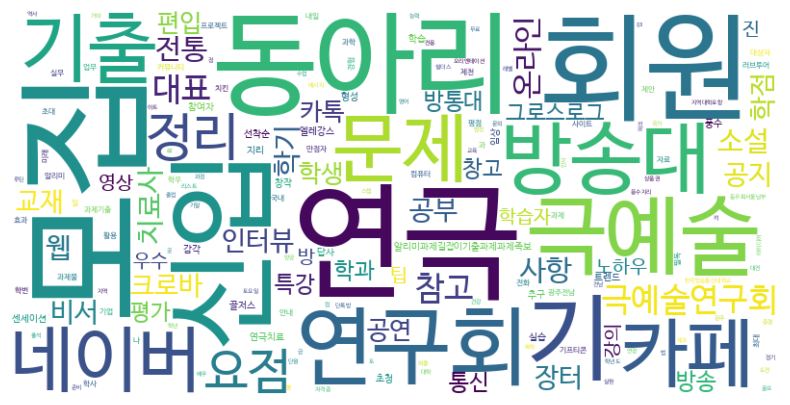

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count) # word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

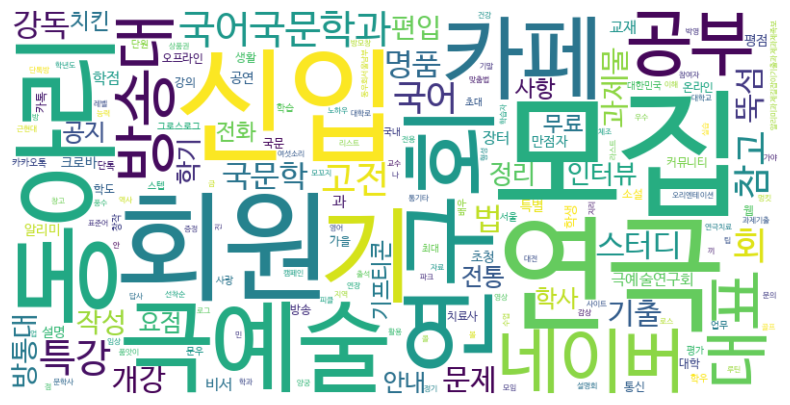

In [14]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

<IPython.core.display.Javascript object>

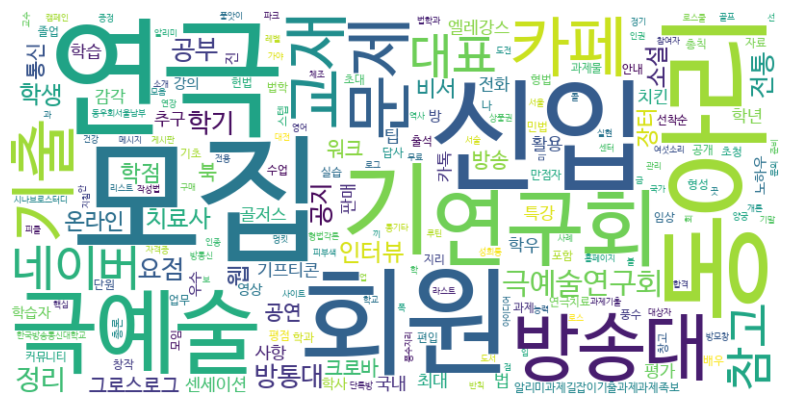

In [15]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


In [16]:
from vllm import LLM

## LLM 모델 로드 및 설정
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct",
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.9,
    max_model_len=4096,
    swap_space=0,
    enforce_eager=True
)

INFO 10-20 13:42:57 [__init__.py:244] Automatically detected platform cuda.


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


INFO 10-20 13:43:17 [config.py:841] This model supports multiple tasks: {'reward', 'generate', 'embed', 'classify'}. Defaulting to 'generate'.
INFO 10-20 13:43:17 [config.py:3368] Downcasting torch.float32 to torch.float16.
INFO 10-20 13:43:17 [config.py:1472] Using max model len 4096
WARNING 10-20 13:43:17 [arg_utils.py:1735] Compute Capability < 8.0 is not supported by the V1 Engine. Falling back to V0. 
WARNING 10-20 13:43:17 [cuda.py:102] To see benefits of async output processing, enable CUDA graph. Since, enforce-eager is enabled, async output processor cannot be used
INFO 10-20 13:43:17 [llm_engine.py:230] Initializing a V0 LLM engine (v0.9.2) with config: model='LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct', speculative_config=None, tokenizer='LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, override_neuron_config={}, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_len=4096, download_dir=None, load_form

Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]


INFO 10-20 13:43:51 [default_loader.py:272] Loading weights took 30.67 seconds
INFO 10-20 13:43:52 [model_runner.py:1203] Model loading took 4.5146 GiB and 31.408373 seconds
INFO 10-20 13:43:54 [worker.py:294] Memory profiling takes 1.71 seconds
INFO 10-20 13:43:54 [worker.py:294] the current vLLM instance can use total_gpu_memory (14.56GiB) x gpu_memory_utilization (0.90) = 13.11GiB
INFO 10-20 13:43:54 [worker.py:294] model weights take 4.51GiB; non_torch_memory takes 0.05GiB; PyTorch activation peak memory takes 0.96GiB; the rest of the memory reserved for KV Cache is 7.59GiB.
INFO 10-20 13:43:54 [executor_base.py:113] # cuda blocks: 6632, # CPU blocks: 0
INFO 10-20 13:43:54 [executor_base.py:118] Maximum concurrency for 4096 tokens per request: 25.91x
INFO 10-20 13:43:54 [llm_engine.py:428] init engine (profile, create kv cache, warmup model) took 2.57 seconds


## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [17]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        # 시스템 메시지 추가
        {"role": "system", "content": "You ar EXAONE model from LG AI Research, a helpful assistant."},
        # 사용자 메시지 추가
        {"role": "user", "content": user_input}
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

INFO 10-20 13:47:29 [chat_utils.py:444] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.


Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


생성된 텍스트: 대한민국의 수도는 **서울**입니다! 서울은 역사와 현대가 공존하는 매력적인 도시로, 다양한 관광 명소와 즐길거리를 제공합니다.

### 여행 추천 즐길거리:
1. **경복궁**: 조선 시대의 웅장한 궁궐로, 전통 건축물과 아름다운 정원을 감상할 수 있습니다. 특히 봄에는 벚꽃이 만발해 더욱 아름답습니다.
   
2. **국립중앙박물관**: 한국의 역사와 문화를 한눈에 볼 수 있는 곳으로, 고대부터 현대까지의 다양한 유물과 전시물을 만나볼 수 있습니다.

3. **한강**: 서울을 가로지르는 한강은 산책하기에 ideal합니다. 특히 밤에는 한강변을 따라 조성된 LED 조명이 아름다운 야경을 선사합니다 (예: 한강공원의 밤 풍경).

4. **명동 및 명동역**: 쇼핑과 문화 체험을 동시에 즐길 수 있는 곳입니다. 다양한 상점과 카페가 즐비해 있어 쇼핑과 휴식을 동시에 만끽할 수 있습니다.

5. **인사동**: 전통 공예품과 예술 작품을 구경하고 구매할 수 있는 곳으로, 한국의 전통문화를 체험하기에 좋습니다. 특히 가을이면 단풍나무가 아름다워 많은 관광객들이 찾습니다.

6. **롯데월드타워**: 서울의 랜드마크 중 하나로, 전망대에서 서울 시내 전경을 감상하거나 테마파크에서 즐거운 시간을 보낼 수 있습니다. 특히 야간 조명 아래서 보는 서울 야경은 매우 인상적입니다.

이러한 장소들은 서울 여행의 핵심 포인트로, 역사와 현대가 어우러진 매력적인 도시 경험이 될 것입니다!


## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [18]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [19]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

'**분류 결과:** 학사/전공  \n**설명:** 딥러닝 개발 과정에서의 질문은 주로 학업 내용과 직접 연관되어 있으며, 컴퓨터학과 학생이나 전공자가 다루는 핵심 주제입니다. 따라서 이 제목은 학업 및 전공 관련 내용에 해당하므로 **학사/전공** 클래스로 분류됩니다.'

In [20]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

'**분류 결과:** 학생활동  \n**이유:** 제목이 "연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!"으로, 주로 학생들의 자발적인 동아리 활동과 관련된 내용을 다루고 있습니다. 특히 "신규 단원 혜택"과 같은 문구는 학생 참여를 유도하는 요소를 포함하고 있어 학생활동 범주에 가장 적합합니다.'

## 13-15 분류 결과 파싱 함수 정의

In [21]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes]

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [ ]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

...

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

## 13-17 분류 결과 시각화

In [ ]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

## 13-18 다른 학과의 분류 결과 시각화

In [ ]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

In [ ]:
plot_class(ko_df)

In [ ]:
plot_class(law_df)